<a href="https://colab.research.google.com/github/dhhung98-bot/Chess/blob/main/Copy_of_lesson02_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 第 2 堂：分數與實驗

上週我們讓電腦亂下，勝率大約 1%。今天要做三件事：

1. 搞懂「累計獎勵」：一整盤棋下來，電腦總共拿了幾分
2. 學會做公平的實驗，讓比較出來的結果可以相信
3. 自己寫兩個比較聰明的策略，看勝率能提高多少

今天的上課方式：

- 看到 **先猜再跑**：執行之前，先在「我猜」那行寫下你的答案和理由。猜錯完全沒關係，猜錯才會記得。
- 看到 **換你講**：用一兩句話講給老師聽，用你自己的話。
- 看到 **改壞看看**：照著把程式改壞，看會發生什麼事，再改回來。
- 有 `# TODO` 的地方是你要寫的。
- 下課前會請你錄一段 2 分鐘的影片，講今天做了什麼。

## 1. 準備：把上週的程式拿回來

下面這格是上週寫好的棋盤程式，做了一個小升級：`step_penalty` 讓我們可以設定「每走一步扣幾分」，之後做實驗會用到。其他都跟上週一樣。

直接執行就好。

In [1]:
!pip install -q chess

import chess
import random
import matplotlib.pyplot as plt


def random_krk_board():
    while True:
        board = chess.Board(None)
        wk, wr, bk = random.sample(chess.SQUARES, 3)
        board.set_piece_at(wk, chess.Piece(chess.KING, chess.WHITE))
        board.set_piece_at(wr, chess.Piece(chess.ROOK, chess.WHITE))
        board.set_piece_at(bk, chess.Piece(chess.KING, chess.BLACK))
        board.turn = chess.WHITE
        if board.is_valid() and not board.is_game_over():
            return board


class KRKEnv:
    def __init__(self, max_steps=50, step_penalty=0.01):
        self.max_steps = max_steps
        self.step_penalty = step_penalty     # 新的：每走一步扣幾分

    def reset(self):
        self.board = random_krk_board()
        self.steps = 0
        self.done = False
        return self.get_state()

    def get_state(self):
        wk = self.board.king(chess.WHITE)
        bk = self.board.king(chess.BLACK)
        rooks = self.board.pieces(chess.ROOK, chess.WHITE)
        if rooks:
            wr = list(rooks)[0]
        else:
            wr = None
        return (wk, wr, bk)

    def legal_actions(self):
        return list(self.board.legal_moves)

    def is_terminal(self):
        return self.done

    def step(self, move):
        self.board.push(move)
        self.steps += 1

        if self.board.is_checkmate():
            self.done = True
            return self.get_state(), 1.0, True

        if self.board.is_stalemate():
            self.done = True
            return self.get_state(), -1.0, True

        black_move = random.choice(list(self.board.legal_moves))
        self.board.push(black_move)

        if self.board.is_insufficient_material():
            self.done = True
            return self.get_state(), -1.0, True

        if self.steps >= self.max_steps:
            self.done = True
            return self.get_state(), -self.step_penalty, True

        return self.get_state(), -self.step_penalty, False


def game_result(env):
    if env.board.is_checkmate():
        return "win"
    if env.board.is_stalemate():
        return "stalemate"
    if env.board.is_insufficient_material():
        return "rook lost"
    return "timeout"

print("準備好了")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 38.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
準備好了


## 2. 暖身：上週的作業一起做

最多走幾步，會不會影響結果？我們把 `max_steps` 改成 30、50、100，各亂下 3000 盤。

**先猜再跑**：最多步數從 50 改成 100，多給它一倍的時間，你覺得會怎樣？

- A. 贏的盤數變成兩倍以上
- B. 贏的盤數只多一點點
- C. 贏的盤數變少

我猜：

因為：

In [2]:
def play_random_game(env):
    env.reset()
    while not env.is_terminal():
        env.step(random.choice(env.legal_actions()))


for max_steps in [30, 50, 100]:
    env = KRKEnv(max_steps=max_steps)
    count = {"win": 0, "stalemate": 0, "rook lost": 0, "timeout": 0}
    for i in range(3000):
        play_random_game(env)
        count[game_result(env)] += 1
    print(max_steps, count)

30 {'win': 13, 'stalemate': 5, 'rook lost': 1557, 'timeout': 1425}
50 {'win': 25, 'stalemate': 12, 'rook lost': 2083, 'timeout': 880}
100 {'win': 28, 'stalemate': 12, 'rook lost': 2678, 'timeout': 282}


看結果回答：步數變多，哪個數字變最多？勝率有跟著變高很多嗎？為什麼？

（寫在這裡）

## 3. 累計獎勵：一整盤拿了幾分

每走一步，環境都會給一個分數（reward）。把一整盤的分數加起來，就是**累計獎勵**（return）。

先用手算：

- 第 12 步將死：前 11 步每步 −0.01，最後一步 +1，合計是多少？
- 第 5 步把車送掉：前 4 步每步 −0.01，最後一步 −1，合計是多少？
- 走滿 50 步都沒結束：每步 −0.01，合計是多少？

算完再用程式檢查。

In [5]:
def total_return(rewards):
    # TODO: 把 rewards 這個 list 裡的數字全部加起來，回傳
    total_score = 0
    for reward in rewards:
        total_score += reward
    return total_score


print(total_return([-0.01] * 11 + [1.0]))    # 第 12 步將死
print(total_return([-0.01] * 4 + [-1.0]))    # 第 5 步送車
print(total_return([-0.01] * 50))            # 時間到

0.89
-1.04
-0.5000000000000002


**換你講**：用一句話跟老師說，累計獎勵是什麼？為什麼要扣「每走一步」的分？

**先猜再算**：如果每步扣 **0.05** 而不是 0.01，「走滿 50 步時間到」和「第 5 步就送車」，哪個分數比較高？先猜，再算。

我猜：

算出來：時間到 = ＿＿＿，送車 = ＿＿＿

想一想：如果電腦的目標是讓分數越高越好，它會學到什麼奇怪的下法？

（寫在這裡）

## 4. 公平的比較：寫一個「裁判」

之後我們會寫很多種下棋策略，需要一個公平的方法來比較。

想法是這樣：**策略**是一個函式，看到棋盤就回傳要走哪一步。**裁判** `evaluate` 不管策略怎麼想，只負責讓它下很多盤、記錄結果。

先看最簡單的策略：亂下。

In [6]:
def random_policy(env):
    return random.choice(env.legal_actions())

Python 可以把函式當成參數傳給另一個函式，就像把一個人推上場比賽。注意傳的時候**不要加括號**：`evaluate(random_policy)` 是把選手交給裁判，`evaluate(random_policy())` 是自己先叫選手走一步，會出錯。

**公平的實驗**有兩個規則：

1. 一次只改一個東西。比較兩個策略時，盤數、最多步數都要一樣。
2. 固定亂數種子。`random.seed(0)` 會讓之後的「亂數」每次都一樣，同樣的程式跑兩次結果會一模一樣。

In [8]:
def evaluate(policy, n=3000, seed=0, max_steps=50, step_penalty=0.01):
    random.seed(seed)
    env = KRKEnv(max_steps=max_steps, step_penalty=step_penalty)
    count = {"win": 0, "stalemate": 0, "rook lost": 0, "timeout": 0}
    total = 0

    for i in range(n):
        env.reset()
        G = 0
        while not env.is_terminal():
            move = policy(env)                  # 問選手要走哪一步
            state, reward, done = env.step(move)
            G += reward                         # 累計獎勵
        count[game_result(env)] += 1
        total += G

    win_rate = count["win"] / n * 100
    return count, round(win_rate, 1), round(total / n, 3)

**先猜再跑**：下面三行都是讓亂下的策略下 3000 盤。第一行和第二行的結果會一模一樣嗎？第三行呢？

我猜：

In [9]:
print(evaluate(random_policy, seed=0))
print(evaluate(random_policy, seed=0))
print(evaluate(random_policy, seed=1))

({'win': 21, 'stalemate': 9, 'rook lost': 2076, 'timeout': 894}, 0.7, -0.973)
({'win': 21, 'stalemate': 9, 'rook lost': 2076, 'timeout': 894}, 0.7, -0.973)
({'win': 24, 'stalemate': 11, 'rook lost': 2106, 'timeout': 859}, 0.8, -0.98)


**換你講**：`evaluate` 裡面 `move = policy(env)` 這一行，是誰決定要走哪一步？

**改壞看看**：把下面這格的 `random_policy` 後面加上括號，變成 `evaluate(random_policy())`，執行看看。讀錯誤訊息的最後一行，跟老師說它在講什麼。看完把括號拿掉。

In [12]:
print(evaluate(random_policy, n=10))

({'win': 0, 'stalemate': 1, 'rook lost': 6, 'timeout': 3}, 0.0, -0.971)


## 5. 第一個聰明的策略：能將死就將死

亂下的電腦連「下一步就能贏」都看不出來。我們教它一件事：**每一步都先偷看，如果有一步走下去就將死，就走那一步；沒有的話才亂走。**

怎麼偷看？用 `push` 先走，用 `is_checkmate()` 檢查，再用 `pop` 收回來，棋盤就跟沒走過一樣：

In [13]:
env = KRKEnv()
env.reset()
move = env.legal_actions()[0]

print("走之前：", env.board.fen())
env.board.push(move)       # 先走走看
print("走之後：", env.board.fen())
env.board.pop()            # 收回來
print("收回來：", env.board.fen())

走之前： 2K2k2/8/8/8/8/8/6R1/8 w - - 0 1
走之後： 3K1k2/8/8/8/8/8/6R1/8 b - - 1 1
收回來： 2K2k2/8/8/8/8/8/6R1/8 w - - 0 1


### 練習 1

寫 `find_mate(env)`：檢查每一個合法走法，如果有一步能將死就回傳那一步，都沒有就回傳 `None`。

然後寫 `mate_policy(env)`：先用 `find_mate` 找，找到就走它，找不到就亂走。

In [22]:
def find_mate(env):
    for move in env.legal_actions():
        # TODO: 先走走看，檢查是不是將死，再收回來
        env.board.push(move)
        check_checkmate = env.board.is_checkmate()
        env.board.pop()
        if check_checkmate:
            return move
        # 如果是將死，回傳 move


    return None


def mate_policy(env):
    # TODO: 用 find_mate 找，找到就回傳那一步，找不到就亂走
    move = find_mate(env)
    if move is not None:
        return move
    return random.choice(env.legal_actions())


檢查：這個局面白車走到 a8 就將死，`find_mate` 應該要找到 `a7a8`。

a7a8


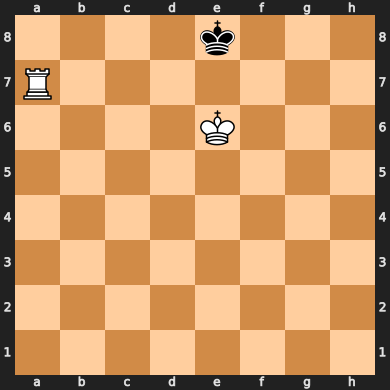

In [23]:
env = KRKEnv()
env.reset()
env.board = chess.Board("4k3/R7/4K3/8/8/8/8/8 w - - 0 1")
print(find_mate(env))      # 應該印出 a7a8
env.board                  # 棋盤應該沒有動過：白車還在 a7

**改壞看看**：在 `find_mate` 裡 `env.board.pop()` 那一行最前面加一個 `#`，把它暫時關掉。重新執行 `find_mate` 那格，再執行上面這格檢查。棋盤發生了什麼事？為什麼？看完記得把 `#` 拿掉，兩格都重新執行。

**先猜再跑**：亂下的勝率是 0.7%。只加了「能將死就將死」這一條規則，你覺得勝率會變多少？

我猜：＿＿＿%

In [25]:
print("亂下　　　　", evaluate(random_policy))
print("能將死就將死", evaluate(mate_policy))

亂下　　　　 ({'win': 21, 'stalemate': 9, 'rook lost': 2076, 'timeout': 894}, 0.7, -0.973)
能將死就將死 ({'win': 242, 'stalemate': 2, 'rook lost': 1951, 'timeout': 805}, 8.1, -0.841)


**換你講**：勝率變高了，可是「車被吃」的盤數幾乎沒變。為什麼？

## 6. 第二個策略：不要送車

看看上面的結果，最常見的輸法還是車被吃掉。所以我們再加一條規則：**不要走那些「走完以後車會被吃掉」的步。**

車什麼時候會被吃？黑王攻擊得到它，而且白王沒有在旁邊保護它。`board.is_attacked_by(顏色, 格子)` 可以檢查某個格子有沒有被某一方攻擊。

In [30]:
def rook_is_safe(board):
    rooks = board.pieces(chess.ROOK, chess.WHITE)
    if not rooks:
        return False
    rook_square = list(rooks)[0]
    attacked = board.is_attacked_by(chess.BLACK, rook_square)    # 黑王打得到嗎
    protected = board.is_attacked_by(chess.WHITE, rook_square)   # 白王顧得到嗎
    return (not attacked) or protected

### 練習 2（老師講、你打字）

寫 `safe_policy(env)`：

1. 能將死就將死（用 `find_mate`）
2. 不然的話，把每一步都偷看一次，留下「走完以後車是安全的，而且不會變成逼和」的步
3. 從留下來的步裡隨機挑一個。如果一步都沒留下，就從全部的步裡亂挑

In [31]:
def safe_policy(env):
    move = find_mate(env)
    if move is not None:
        return move

    good_moves = []
    for move in env.legal_actions():
        # TODO: 先走走看
        env.board.push(move)
        # TODO: 如果車安全、而且沒有逼和，就把 move 加進 good_moves
        if rook_is_safe(env.board) and not env.board.is_stalemate():
            good_moves.append(move)
        # TODO: 收回來
        env.board.pop()

    # TODO: good_moves 有東西就從裡面挑，沒有就從全部的步裡挑
    if good_moves:
        return random.choice(good_moves)
    return random.choice(env.legal_actions())

    # TODO: good_moves 有東西就從裡面挑，沒有就從全部的步裡挑

**先猜再跑**：「不送車」的勝率大概是多少？它最常怎麼結束（將死、車被吃、時間到）？

我猜：勝率＿＿＿%，最常的結局是＿＿＿

In [32]:
results = {}
results["random"] = evaluate(random_policy)
results["mate"] = evaluate(mate_policy)
results["safe"] = evaluate(safe_policy)

for name in results:
    print(name, results[name])

random ({'win': 21, 'stalemate': 9, 'rook lost': 2076, 'timeout': 894}, 0.7, -0.973)
mate ({'win': 242, 'stalemate': 2, 'rook lost': 1951, 'timeout': 805}, 8.1, -0.841)
safe ({'win': 368, 'stalemate': 0, 'rook lost': 0, 'timeout': 2632}, 12.3, -0.343)


畫成圖比較（圖上的字用英文，因為 Colab 預設沒有中文字型）：

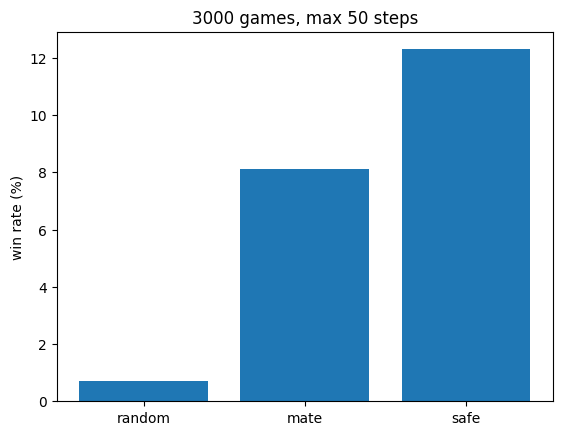

In [33]:
names = list(results.keys())
win_rates = [results[name][1] for name in names]

plt.bar(names, win_rates)
plt.ylabel("win rate (%)")
plt.title("3000 games, max 50 steps")
plt.show()

看結果回答：

1. 「不送車」的策略，車還會被吃掉嗎？
2. 它最常見的結局變成什麼？為什麼不輸了，卻還是贏不了？
3. 如果要讓它真的會將死，你還需要寫哪些規則？試著列出來。

（寫在這裡）

## 7. 存到 GitHub，在 README 加結果表

1. 「檔案 → 在 GitHub 中儲存副本」，檔名 `lesson02.ipynb`，訊息寫清楚，例如：`第2堂：evaluate、能將死就將死、不送車策略`
2. 到 GitHub 打開 `README.md`，按鉛筆圖示，加一個結果表。Markdown 的表格長這樣（數字換成你自己跑出來的）：

```
| 策略 | 勝率 | 車被吃 | 時間到 |
|---|---|---|---|
| 亂下 | 0.7% | 2076 | 894 |
| 能將死就將死 | 8.1% | 1951 | 805 |
| 不送車 | 12.3% | 0 | 2632 |
```

3. 按 Commit changes，訊息寫 `README：加入第2堂的策略比較`

之後每一堂，都在這個表加新的一列，最後就是你整個專案的進步紀錄。

## 下課前：錄 2 分鐘

用手機或電腦對著自己錄一段 2 分鐘左右的影片，回答這三個問題。不用背稿，講錯也沒關係：

1. 今天做了什麼？
2. 哪裡最難？你是怎麼弄懂的（或是還沒懂）？
3. 下一步你想讓這個程式變成怎樣？

錄好的影片自己留著。之後八堂課的影片放在一起，就是你這個專案的學習紀錄。

## 8. 作業（約 2 到 3 小時）

每做完一題就存一次 GitHub，commit 訊息寫清楚做了哪一題。

### 第 1 題：分數設計會改變誰比較好

用 `evaluate` 的 `step_penalty` 參數，把每步扣分改成 0、0.01、0.05，三個策略都跑，看第三個數字（平均累計獎勵），填這個表：

| 策略 | 扣 0 | 扣 0.01 | 扣 0.05 |
|---|---|---|---|
| 亂下 | | | |
| 能將死就將死 | | | |
| 不送車 | | | |

然後回答：扣 0.05 的時候，哪個策略的分數最高？跟勝率的排名一樣嗎？為什麼？

### 第 2 題：種子

用 `random.seed` 做一個小實驗，證明「同樣的種子，結果一樣；不同的種子，結果不一樣」。用一兩句話說明為什麼做實驗要固定種子。

### 第 3 題：想一想

如果要你把「不送車」改成「真的會將死」，你會怎麼做？寫下你的想法就好，不用寫程式。下週上課第一件事就是聽你講。

In [ ]:
# 第 1 題寫在這裡

In [ ]:
# 第 2 題寫在這裡

第 3 題寫在這裡：